In [229]:
import pandas as pd
import altair as alt
from base_utils import read_model_configs, create_all_agent_response_dataframe, get_all_test_types, prepare_dataframe, prepare_response_dataframe
from base_utils import find_correct_mc, find_min_max_scaled_error
import numpy as np
import math

In [2]:
from joblib import Parallel, delayed
from numpy.random import Generator, PCG64
alt.renderers.enable("mimetype")
alt.data_transformers.disable_max_rows()

DataTransformerRegistry.enable('default')

In [4]:
all_dfs = []
test_types = ['ggr', 'vlat', 'holf', 'calvi-trick', 'calvi-standard', 'holf2', 'chartqa-test-continuous-human']
for test_type in test_types:
    model_response = prepare_dataframe(test_type)
    model_response['test_type'] = test_type
    all_dfs.append(model_response)

all_dfs = pd.concat(all_dfs).replace({"calvi-trick": "calvi", "calvi-standard": "calvi"})

In [5]:
# all_dfs[all_dfs['test_type'] == 'calvi-trick'][['image_file', 'question']].drop_duplicates()

In [6]:
len(all_dfs[all_dfs['test_type'] == 'calvi'][['question', 'image_file']].drop_duplicates())

60

# Valid Responses

In [34]:
a = pd.read_csv("/Users/arnav/Desktop/contextvis/vlm-datavis-benchmark/analysis/tacl_analysis/valid_df/GPT-4V.csv")

# Accuracy Plots

In [35]:
pd.read_csv("/Users/arnav/Desktop/contextvis/vlm-datavis-benchmark/analysis/tacl_analysis/ci_df/vlat.csv").sort_values('mean', ascending=False)

,Unnamed: 0,agentType,ci_upper,ci_lower,value_count,mean
8,8,Human,0.768412,0.683182,1.000000,0.725492
7,7,GPT-4V,0.711599,0.519174,0.981132,0.615686
5,5,google/pix2struct-chartqa-base,0.756098,0.280000,0.339623,0.485714
4,4,liuhaotian/llava-v1.6-34b,0.560554,0.390000,0.962264,0.475904
6,6,google/matcha-chartqa,0.735294,0.206897,0.245283,0.451613
3,3,llava-hf/llava-1.5-13b-hf,0.526480,0.357893,0.943396,0.442623
2,2,llava-hf/llava-1.5-7b-hf,0.493939,0.300000,0.943396,0.398000
1,1,Salesforce/blip2-flan-t5-xxl,0.426667,0.298694,0.962264,0.363257
0,0,Salesforce/blip2-flan-t5-xl,0.426428,0.266656,0.962264,0.347305


In [6]:
a = pd.read_csv("https://data-visualization-benchmark.s3.us-west-2.amazonaws.com/holf2/responses/indist_instructions_question/pna/tna/Human/processed_extracted_responses.csv")

In [7]:
test = pd.read_csv("/Users/arnav/Desktop/contextvis/vlm-datavis-benchmark/analysis/tacl_analysis/heatmap/correlation_matrix.csv")

In [10]:
# pd.read_csv("/Users/arnav/Desktop/contextvis/vlm-datavis-benchmark/analysis/tacl_analysis/ci_df/vlat.csv").sort_values('mean', ascending=False)

# Statistical Contrasts

In [11]:
def bootstrap_pairwise_ci( 
        raw_data,
        units_of_measure,
        n_iterations=1000,
        statistic=np.mean,
    ):
    
    data = raw_data.copy()
    data["question_image"] = data["question"] + " & " + data["image_file"]
    rng = Generator(PCG64())
    questions = list(data["question_image"].unique())
    n_size = len(questions)
    df = data.copy()

    # sample within the data
    df = df.sample(frac=1, replace=True, random_state=1)

    def bootstrap_iteration(data, chosen_qs):
        filter_df = data[data["question_image"].isin(chosen_qs)] # Filter based on chosen questions
        bs_mean = statistic(filter_df[units_of_measure]) # Calculate mean of the filtered data
        return bs_mean
    means = Parallel(n_jobs=-1)(
        delayed(bootstrap_iteration)(df, rng.choice(questions, n_size,  replace=True)) for _ in range(n_iterations)
    )
    
    # 95% confidence interval
    lower = np.percentile(means, 2.5)
    upper = np.percentile(means, 97.5)
    
    return lower, upper


def create_pairwise_confidence_interval_df(agent_res, units_of_measure, statistic=np.mean):
    
    lower, upper = bootstrap_pairwise_ci(agent_res, statistic=statistic, units_of_measure=units_of_measure)
    stats = {
        "ci_upper": upper, 
        "ci_lower": lower,
        "mean": statistic(agent_res[units_of_measure])
    }
    return stats

In [9]:
all_dfs[(all_dfs['test_type'] == 'holf2') & (all_dfs['agentType'] == 'google/matcha-chartqa')]['is_correct'].median()

0.4508333333333333

In [10]:
# all_dfs

In [11]:
def between_human_model_comparison(data, tests=[], statistic=np.mean):
    
    
    df = data.copy().replace(agent_map).dropna()
    df = df[df['test_type'].isin(tests)]
    return create_pairwise_confidence_interval_df(df, units_of_measure='is_correct', statistic=statistic)

between_human_model_comparison(
    all_dfs,
    tests=['ggr', 'vlat', 'calvi-trick'], 
    statistic=np.mean
)

NameError: name 'agent_map' is not defined

In [ ]:
# all_dfs

In [119]:
def dom_bootstrap_ci(
    raw_data,
    col1,
    col2,
    n_iterations=1000,
    statistic=np.mean,
    units_of_measure="is_correct",
):
    
    data = raw_data.copy()
    data["question_image"] = data["question"] + " & " + data["image_file"]
    rng = Generator(PCG64())
    questions = list(data["question_image"].unique())
    n_size = len(questions)
    df = data.copy()

    def bootstrap_iteration(data, chosen_qs):
        filter_df = data[data["question_image"].isin(chosen_qs)] # Filter based on chosen questions
        col1_res = filter_df[(filter_df["agentType"] == col1)][units_of_measure]
        col2_res = filter_df[(filter_df["agentType"] == col2)][units_of_measure]
        
        bs_mean = statistic(col1_res) - statistic(col2_res)
        return bs_mean
        
    means = Parallel(n_jobs=-1)(
        delayed(bootstrap_iteration)(df, rng.choice(questions, n_size,  replace=True)) for _ in range(n_iterations)
    )
    
    # 95% confidence interval
    lower = np.percentile(means, 2.5)
    upper = np.percentile(means, 97.5)
    
    return lower, upper

def create_confidence_interval_dom_df(data, col1, col2, units_of_measure, statistic=np.mean):
    data_list = []
    lower, upper = dom_bootstrap_ci(
        data, 
        col1,
        col2,
        statistic=statistic, 
        units_of_measure=units_of_measure
    )

    data_list.append({
        # "agentType": agent,
        "ci_upper": upper, 
        "ci_lower": lower,
        "mean": (
            statistic(data[data["agentType"] == col1][units_of_measure]) - 
            statistic(data[data["agentType"] == col2][units_of_measure]))
    })

    return pd.DataFrame(data_list)

In [ ]:
agent_map = {
    "llava-hf/llava-1.5-7b-hf": np.nan,
    "llava-hf/llava-1.5-13b-hf":  np.nan,
    "liuhaotian/llava-v1.6-34b": np.nan,
    'Salesforce/blip2-flan-t5-xl':  np.nan,
    'Salesforce/blip2-flan-t5-xxl':  np.nan,
    "google/pix2struct-chartqa-base":  np.nan,
    "google/matcha-chartqa":  np.nan,
    'GPT-4V':  "model",
    'Human': 'human',
}

In [ ]:
# all_dfs

In [ ]:
human_model_mc = all_dfs.copy()
human_model_mc['agentType'] = human_model_mc['agentType'].replace(agent_map)
human_model_mc = human_model_mc[human_model_mc['test_type'].isin(['ggr','vlat','calvi-trick'])]

create_confidence_interval_dom_df(
    human_model_mc, 
    col1="model", 
    col2="human", 
    units_of_measure='is_correct'
)

In [327]:
human_model_error = all_dfs.copy()
human_model_error['agentType'] = human_model_error['agentType'].replace(agent_map)
numerical_tests = ['holf','holf2','chartqa-test-continuous-human']
human_model_error = human_model_error[human_model_error['test_type'].isin(numerical_tests)]

create_confidence_interval_dom_df(
    human_model_error, 
    col1="human", 
    col2="model", 
    units_of_measure='is_correct',
    statistic=np.median
)

,ci_upper,ci_lower,mean
0,-0.043654,-0.066613,-0.055167


## GPT-4V vs Human

### in GGR

In [132]:
agent_map = {
    "llava-hf/llava-1.5-7b-hf": np.nan,
    "llava-hf/llava-1.5-13b-hf": np.nan,
    "liuhaotian/llava-v1.6-34b": np.nan,
    'Salesforce/blip2-flan-t5-xl': np.nan,
    'Salesforce/blip2-flan-t5-xxl': np.nan,
    "google/pix2struct-chartqa-base": np.nan,
    "google/matcha-chartqa": np.nan,
    'GPT-4V': "Model",
    'Human': "Human",
}

human_model_error = all_dfs.copy()
human_model_error['agentType'] = human_model_error['agent_type'].replace(agent_map)

human_model_error = human_model_error[human_model_error['test_type'] == 'ggr']
human_model_error = human_model_error.dropna(subset=['agentType'])

create_confidence_interval_dom_df(
    human_model_error, 
    col1="Human", 
    col2="Model", 
    units_of_measure='is_correct',
    statistic=np.mean
)

,ci_upper,ci_lower,mean
0,0.755032,0.417918,0.578388


### in VLAT

In [133]:
human_model_error = all_dfs.copy()
human_model_error['agentType'] = human_model_error['agent_type'].replace(agent_map)

human_model_error = human_model_error[human_model_error['test_type'] == 'vlat']
human_model_error = human_model_error.dropna(subset=['agentType'])

create_confidence_interval_dom_df(
    human_model_error, 
    col1="Human", 
    col2="Model", 
    units_of_measure='is_correct',
    statistic=np.mean
)

,ci_upper,ci_lower,mean
0,0.196133,0.005647,0.102416


### in CALVI trick

In [ ]:
calvi_df = corr_df[corr_df['test_type'] == 'calvi'].copy()
# calvi_df['agent_type'] = calvi_df['agent_type'].apply(lambda a : "Human" if "Human" == a else "Model")

In [140]:
human_model_error = all_dfs.copy()
human_model_error['agentType'] = human_model_error['agent_type'].replace(agent_map)
human_model_error = human_model_error[human_model_error['test_type'] == 'calvi']
human_model_error = human_model_error.dropna(subset=['agentType'])

sort_calvi = lambda r : "calvi-standard" if r['image_file'].find("N") != -1 else "calvi-trick"
human_model_error['test_type'] = human_model_error.apply(sort_calvi, axis=1)
human_model_error = human_model_error[human_model_error['test_type'] != 'calvi-trick']

create_confidence_interval_dom_df(
    human_model_error, 
    col1="Human", 
    col2="Model", 
    units_of_measure='is_correct',
    statistic=np.mean
)

,ci_upper,ci_lower,mean
0,0.551581,0.128859,0.327216


In [141]:
human_model_error = all_dfs.copy()
human_model_error['agentType'] = human_model_error['agent_type'].replace(agent_map)
human_model_error = human_model_error[human_model_error['test_type'] == 'calvi']
human_model_error = human_model_error.dropna(subset=['agentType'])

sort_calvi = lambda r : "calvi-standard" if r['image_file'].find("N") != -1 else "calvi-trick"
human_model_error['test_type'] = human_model_error.apply(sort_calvi, axis=1)
human_model_error = human_model_error[human_model_error['test_type'] == 'calvi-trick']

create_confidence_interval_dom_df(
    human_model_error, 
    col1="Human", 
    col2="Model", 
    units_of_measure='is_correct',
    statistic=np.mean
)

,ci_upper,ci_lower,mean
0,0.187312,-0.025601,0.076238


### Numerical tests performance difference

In [226]:
# cohen'd 
human_model_error = all_dfs.copy()
human_model_error['agentType'] = human_model_error['agent_type'].replace(agent_map)
human_model_error = human_model_error[human_model_error['test_type'].isin(['holf', 'holf2', 'chartqa-test-continuous-human'])]
human_model_error = human_model_error.dropna(subset=['agentType'])


human_model_error_mc = all_dfs.copy()
human_model_error_mc['agentType'] = human_model_error_mc['agent_type'].replace(agent_map)
human_model_error_mc = human_model_error_mc[human_model_error_mc['test_type'].isin(['ggr', 'vlat', 'calvi'])]
human_model_error_mc = human_model_error_mc.dropna(subset=['agentType'])

In [227]:
# human_model_error_mc

In [228]:
create_confidence_interval_dom_df(
    human_model_error, 
    col1="Human", 
    col2="Model", 
    units_of_measure='is_correct',
    statistic=np.median
)

,ci_upper,ci_lower,mean
0,-0.044446,-0.066397,-0.057428


In [190]:
human_model_error = human_model_error.pivot(index=['question', 'image_file'], columns=['agentType'], values=['is_correct']).reset_index()
human_model_error_mc = human_model_error_mc.pivot(index=['question', 'image_file'], columns=['agentType'], values=['is_correct']).reset_index()

In [196]:
human_model_error['hm_diff'] = human_model_error['is_correct', 'Human'] - human_model_error['is_correct', 'Model']
human_model_error_mc['hm_diff'] = human_model_error_mc['is_correct', 'Human'] - human_model_error_mc['is_correct', 'Model']

In [211]:
human_model_error['hm_diff'].std()

9639.031614817246

In [219]:
def cohen_d(x, y):
    mean_x = x.mean()
    mean_y = y.median()
    
    std_x = np.std(x, ddof=1)
    std_y = np.std(y, ddof=1)
    
    pooled_std = np.sqrt((std_x ** 2 + std_y ** 2) / 2)
    
    d = (mean_x - mean_y) / pooled_std
    return d

cohen_d(human_model_error_mc['hm_diff'], human_model_error['hm_diff'])

3.062316837839541e-05

# GPT-4V vs Models

In [98]:
agent_map = {
    "llava-hf/llava-1.5-7b-hf": "model",
    "llava-hf/llava-1.5-13b-hf": "model",
    "liuhaotian/llava-v1.6-34b": "model",
    'Salesforce/blip2-flan-t5-xl': "model",
    'Salesforce/blip2-flan-t5-xxl': "model",
    "google/pix2struct-chartqa-base": "model",
    "google/matcha-chartqa": "model",
    'GPT-4V': "GPT-4V",
    'Human': np.nan,
}
human_model_error = all_dfs.copy()
human_model_error['agentType'] = human_model_error['agentType'].replace(agent_map)
numerical_tests = ['holf','holf2','chartqa-test-continuous-human']
mc_tests = ['ggr','vlat','calvi-trick']
human_model_error = human_model_error[human_model_error['test_type'].isin(mc_tests)]
human_model_error = human_model_error.dropna(subset=['agentType'])

create_confidence_interval_dom_df(
    human_model_error, 
    col1="GPT-4V", 
    col2="model", 
    units_of_measure='is_correct',
    statistic=np.mean
)

,ci_upper,ci_lower,mean
0,0.213766,0.083206,0.147533


In [104]:
agent_map = {
    "llava-hf/llava-1.5-7b-hf": np.nan,
    "llava-hf/llava-1.5-13b-hf": np.nan,
    "liuhaotian/llava-v1.6-34b": "model",
    'Salesforce/blip2-flan-t5-xl': np.nan,
    'Salesforce/blip2-flan-t5-xxl': np.nan,
    "google/pix2struct-chartqa-base": np.nan,
    "google/matcha-chartqa": np.nan,
    'GPT-4V': "big_model",
    'Human': np.nan,
}
human_model_error = all_dfs.copy()
human_model_error['agentType'] = human_model_error['agentType'].replace(agent_map)
numerical_tests = ['holf', 'holf2', 'chartqa-test-continuous-human']
mc_tests = ['ggr','vlat','calvi-trick']
human_model_error = human_model_error[human_model_error['test_type'].isin(numerical_tests)]
human_model_error = human_model_error.dropna(subset=['agentType'])

create_confidence_interval_dom_df(
    human_model_error, 
    col1="big_model", 
    col2="model", 
    units_of_measure='is_correct',
    statistic=np.median
)

,ci_upper,ci_lower,mean
0,0.011001,-0.01107,0.0


# Correlation CIs

In [7]:
from create_correlation_heatmap import create_correlation_matrix

In [9]:
all_response_dfs = []
test_types = ['ggr', 'vlat', 'calvi-trick', 'calvi-standard']
for test_type in test_types:
    model_response = prepare_response_dataframe(test_type)
    model_response['test_type'] = test_type
    all_response_dfs.append(model_response)

all_response_dfs = pd.concat(all_response_dfs).replace({"calvi-trick": "calvi", "calvi-standard": "calvi"})
print(all_response_dfs['agent_type'].unique())

['Salesforce/blip2-flan-t5-xl' 'Salesforce/blip2-flan-t5-xxl'
 'llava-hf/llava-1.5-7b-hf' 'llava-hf/llava-1.5-13b-hf'
 'liuhaotian/llava-v1.6-34b' 'google/pix2struct-chartqa-base'
 'google/matcha-chartqa' 'GPT-4V' 'Human']


In [233]:
# all_response_dfs

In [12]:
def prepare_dataframe_corr(test_type):
    model_configs = read_model_configs()
    model_responses = create_all_agent_response_dataframe(
        test_name=test_type, 
        model_configs=model_configs,
        print_stats=False
    )
    if test_type in ['ggr', 'vlat', 'calvi-trick', 'calvi-standard']:
        model_responses = find_correct_mc(model_responses_raw=model_responses)
        model_responses = model_responses.groupby(['agent_type', 'question', 'image_file',])['is_correct'].mean().reset_index()
    else:
        model_responses = find_min_max_scaled_error(
            model_responses_raw=model_responses, 
            test_name=test_type,
            units_of_measure="is_correct"
        )
        model_responses = model_responses.dropna(subset=['is_correct'])
        model_responses = model_responses.groupby(['agent_type', 'question', 'image_file',])['is_correct'].median().reset_index()
    
    model_responses = model_responses.sort_values(by=['question', 'image_file'])

    return model_responses

model_responses = []
for test_type in ['ggr', 'vlat', 'calvi-trick', 'calvi-standard']:
    model_response = prepare_dataframe_corr(test_type)
    model_responses.append(model_response)

model_responses = pd.concat(model_responses).replace({"calvi-trick": "calvi", "calvi-standard": "calvi"})

In [236]:
agent_map = {
    "llava-hf/llava-1.5-7b-hf": 'model',
    "llava-hf/llava-1.5-13b-hf": 'model',
    "liuhaotian/llava-v1.6-34b": 'model',
    'Salesforce/blip2-flan-t5-xl': 'model',
    'Salesforce/blip2-flan-t5-xxl': 'model',
    "google/pix2struct-chartqa-base": 'model',
    "google/matcha-chartqa": 'model',
    'GPT-4V': 'model',
    'Human': "Humans",
}

human_model_error = all_response_dfs.copy()
human_model_error['agent_type'] = human_model_error['agent_type'].replace(agent_map)
human_model_error = human_model_error.dropna(subset=['agent_type'])
human_model_error = human_model_error.groupby(['agent_type', 'question', 'image_file',])['is_correct'].mean().reset_index()

In [237]:
def correlation_bootstrap_ci(
    raw_data,
    model_configs,
    n_iterations=1000,
):
    
    data = raw_data.copy()
    data["question_image"] = data["question"] + " & " + data["image_file"]
    rng = Generator(PCG64())
    questions = list(data["question_image"].unique())
    n_size = len(questions)
    df = data.copy()

    def bootstrap_iteration(data, chosen_qs):
        filter_df = data[data["question_image"].isin(chosen_qs)] # Filter based on chosen questions
        corr_matrix = create_correlation_matrix(filter_df, model_configs=model_configs)
        return corr_matrix['correlation'].iloc[1]
        
    means = Parallel(n_jobs=-1)(
        delayed(bootstrap_iteration)(df, rng.choice(questions, n_size,  replace=True)) for _ in range(n_iterations)
    )
    
    # 95% confidence interval
    lower = np.percentile(means, 2.5)
    upper = np.percentile(means, 97.5)
    mean_corr = create_correlation_matrix(raw_data, model_configs=model_configs)['correlation'].iloc[1]
    
    return {
        "ci_upper": upper, 
        "ci_lower": lower,
        "mean": mean_corr
    }

In [240]:
human_model_error['agentType'] = human_model_error['agent_type']

In [244]:
model_configs = [{"model": "Humans"}, {"model": "model"}]
human_model_error['agentType'] = human_model_error['agent_type'].copy()
correlation_bootstrap_ci(
    human_model_error,
    model_configs=model_configs,
    n_iterations=1000,
)

In [241]:
model_configs = [{"model": "Humans"}, {"model": "model"}]

correlation_bootstrap_ci(
    human_model_error,
    model_configs=model_configs,
    n_iterations=1000,
)

{'ci_upper': 0.451967935222956,
 'ci_lower': 0.19653997947861032,
 'mean': 0.32478712891173467}

## MORE CI STUFF

In [248]:
agent_map = {
    "llava-hf/llava-1.5-7b-hf": np.nan,
    "llava-hf/llava-1.5-13b-hf": np.nan,
    "liuhaotian/llava-v1.6-34b": np.nan,
    'Salesforce/blip2-flan-t5-xl': np.nan,
    'Salesforce/blip2-flan-t5-xxl': np.nan,
    "google/pix2struct-chartqa-base": 'model2',
    "google/matcha-chartqa": 'model1',
    'GPT-4V': np.nan,
    'Human': np.nan,
}

human_model_error = all_response_dfs.copy()
human_model_error['agent_type'] = human_model_error['agent_type'].replace(agent_map)
human_model_error = human_model_error.dropna(subset=['agent_type'])
human_model_error = human_model_error.groupby(['agent_type', 'question', 'image_file',])['is_correct'].mean().reset_index()
model_configs = [{"model": "model1"}, {"model": "model2"}]
human_model_error['agentType'] = human_model_error['agent_type'].copy()

correlation_bootstrap_ci(
    human_model_error,
    model_configs=model_configs,
    n_iterations=1000,
)

{'ci_upper': 0.9567009988495109,
 'ci_lower': 0.7548413784817402,
 'mean': 0.859161667004803}

In [18]:
# human_model_error

In [249]:
agent_map = {
    "llava-hf/llava-1.5-7b-hf": 'model1',
    "llava-hf/llava-1.5-13b-hf": np.nan,
    "liuhaotian/llava-v1.6-34b": np.nan,
    'Salesforce/blip2-flan-t5-xl': np.nan,
    'Salesforce/blip2-flan-t5-xxl': np.nan,
    "google/pix2struct-chartqa-base": np.nan,
    "google/matcha-chartqa": 'model2',
    'GPT-4V': np.nan,
    'Human': np.nan,
}

human_model_error = all_response_dfs.copy()
human_model_error['agent_type'] = human_model_error['agent_type'].replace(agent_map)
human_model_error = human_model_error.dropna(subset=['agent_type'])
human_model_error = human_model_error.groupby(['agent_type', 'question', 'image_file',])['is_correct'].mean().reset_index()
model_configs = [{"model": "model1"}, {"model": "model2"}]
human_model_error['agentType'] = human_model_error['agent_type'].copy()

correlation_bootstrap_ci(
    human_model_error,
    model_configs=model_configs,
    n_iterations=1000,
)

{'ci_upper': 0.049832694042780165,
 'ci_lower': -0.32441021510394236,
 'mean': -0.14239824382769484}

In [250]:
agent_map = {
    "llava-hf/llava-1.5-7b-hf": 'model1',
    "llava-hf/llava-1.5-13b-hf": np.nan,
    "liuhaotian/llava-v1.6-34b": np.nan,
    'Salesforce/blip2-flan-t5-xl': np.nan,
    'Salesforce/blip2-flan-t5-xxl': np.nan,
    "google/pix2struct-chartqa-base": 'model2',
    "google/matcha-chartqa": np.nan,
    'GPT-4V': np.nan,
    'Human': np.nan,
}

human_model_error = all_response_dfs.copy()
human_model_error['agent_type'] = human_model_error['agent_type'].replace(agent_map)
human_model_error = human_model_error.dropna(subset=['agent_type'])
human_model_error = human_model_error.groupby(['agent_type', 'question', 'image_file',])['is_correct'].mean().reset_index()
model_configs = [{"model": "model1"}, {"model": "model2"}]
human_model_error['agentType'] = human_model_error['agent_type'].copy()

correlation_bootstrap_ci(
    human_model_error,
    model_configs=model_configs,
    n_iterations=1000,
)

{'ci_upper': 0.04757762681274893,
 'ci_lower': -0.35372490443721644,
 'mean': -0.1535651229767737}

## GPT-4V vs Humans

# Model ANOVA

In [22]:
import statsmodels.api as sm
import statsmodels.formula.api as smf
from scipy.stats import chi2
from statsmodels.stats.anova import anova_lm

In [25]:
# all_dfs['test_type'].unique()

In [82]:
corr_df = all_dfs[all_dfs['test_type'].isin(['ggr', 'vlat', 'calvi'])].copy()
corr_df['item'] = corr_df['question'] + " & " + corr_df['image_file']

In [83]:
questions = []
for test_name in ['ggr', 'vlat', 'calvi']:
    AWS_PREFIX = "https://data-visualization-benchmark.s3.us-west-2.amazonaws.com"
    question_set = pd.read_csv(f'{AWS_PREFIX}/{test_name}/questions.csv')
    questions.append(question_set)
questions = pd.concat(questions).reset_index()
corr_df = corr_df.merge(questions[['image_file', 'question', 'chart_type']], on=['image_file', 'question'])
corr_df = corr_df.replace({
    'Line Chart': "line", 
    'Pie Chart': "pie", 
    'Bar Chart': "bar", 
    'Dot Plot': "dot plot", 
    'Scatterplot': 'scatter',
    'Bubble Chart': 'bubble', 
    'Stacked Bar Chart': "stacked bar", 
    'Stacked Area Chart': "stacked area",
    'Treemap': 'treemap', 
    'Histogram': 'histogram', 
    'Choropleth Map': 'map', 
    'Area Chart': 'area',
    '100 % Stacked Bar Chart': '100% stacked bar', 
    'Stacked area chart': 'stacked area', 
    'Bar chart': 'bar',
    'Stacked bar chart': 'stacked bar', 
    'Area chart': 'area', 
    'Choropleth map': 'map', 
    'Line chart': 'line',
    'Pie chart': 'pie', 
    '100% stacked bar chart': '100% stacked bar'
})

In [85]:
corr_df['chart_type'].nunique()

13

In [15]:
# model = smf.mixedlm("is_correct ~ agentType", corr_df, groups=corr_df["item"])
# null_model = smf.mixedlm("is_correct ~ 1", corr_df, groups=corr_df["item"])
# null_result = null_model.fit()
# main_result = model.fit()
# corr_df.to_csv("./corr_df.csv")

In [16]:
# print(main_result.summary())

In [17]:
# print(null_result.summary())

In [18]:
# anova_lm(main_result, null_result)
# lr_stat = 2 * (main_result.llf - null_result.llf)
# df_diff = main_result.df_modelwc - null_result.df_modelwc
# p_value = chi2.sf(lr_stat, df_diff)

In [19]:
# p_value

In [27]:
%load_ext rpy2.ipython
# %reload_ext rpy2.ipython

In [ ]:
# %%R
# install.packages("Matrix")
# library(Matrix)

In [28]:
%%R
install.packages("lme4")
library(lme4)

--- Please select a CRAN mirror for use in this session ---
Secure CRAN mirrors 

 1: 0-Cloud [https]
 2: Australia (Canberra) [https]
 3: Australia (Melbourne 1) [https]
 4: Australia (Melbourne 2) [https]
 5: Austria [https]
 6: Belgium (Brussels) [https]
 7: Brazil (PR) [https]
 8: Brazil (SP 1) [https]
 9: Brazil (SP 2) [https]
10: Bulgaria [https]
11: Canada (MB) [https]
12: Canada (ON 1) [https]
13: Canada (ON 2) [https]
14: Chile (Santiago) [https]
15: China (Beijing 2) [https]
16: China (Beijing 3) [https]
17: China (Hefei) [https]
18: China (Hong Kong) [https]
19: China (Guangzhou) [https]
20: China (Jinan) [https]
21: China (Lanzhou) [https]
22: China (Nanjing) [https]
23: China (Shanghai 2) [https]
24: China (Shenzhen) [https]
25: Colombia (Cali) [https]
26: Costa Rica [https]
27: Cyprus [https]
28: Czech Republic [https]
29: Denmark [https]
30: East Asia [https]
31: Ecuador (Cuenca) [https]
32: France (Lyon 1) [https]
33: France (Lyon 2) [https]
34: France (Marseille) [http

Selection:  70



The downloaded binary packages are in
	/var/folders/v8/3zpbxkws53b3x6m8509jyml80000gn/T//RtmplfmdRV/downloaded_packages


trying URL 'https://ftp.osuosl.org/pub/cran/bin/macosx/big-sur-arm64/contrib/4.4/lme4_1.1-35.5.tgz'
Content type 'application/x-gzip' length 7080907 bytes (6.8 MB)
downloaded 6.8 MB

Loading required package: Matrix
In addition: Warning message:
In doTryCatch(return(expr), name, parentenv, handler) :
  unable to load shared object '/Library/Frameworks/R.framework/Resources/modules//R_X11.so':
  dlopen(/Library/Frameworks/R.framework/Resources/modules//R_X11.so, 0x0006): Library not loaded: /opt/X11/lib/libSM.6.dylib
  Referenced from: <31EADEB5-0A17-3546-9944-9B3747071FE8> /Library/Frameworks/R.framework/Versions/4.4-arm64/Resources/modules/R_X11.so
  Reason: tried: '/opt/X11/lib/libSM.6.dylib' (no such file), '/System/Volumes/Preboot/Cryptexes/OS/opt/X11/lib/libSM.6.dylib' (no such file), '/opt/X11/lib/libSM.6.dylib' (no such file), '/usr/local/lib/libSM.6.dylib' (no such file), '/usr/lib/libSM.6.dylib' (no such file, not in dyld cache)


In [1]:
%%R -i corr_df

# corr_df <- read.csv("./corr_df.csv")

# Model 1: Random intercepts model
model1 <- lmer(is_correct ~ 1 + (1|item), data=corr_df)

# Model 2: Model with agentType as a fixed effect
model2 <- lmer(is_correct ~ agent_type + (1|item), data=corr_df)

# summary(model1)
# summary(model2)
anova(model1, model2)

UsageError: Cell magic `%%R` not found.


In [22]:
%%R

corr_df <- read.csv("./corr_df.csv")

# Model 1: Random intercepts model
model1 <- lmer(is_correct ~ 1 + (1|item), data=corr_df)

# Model 2: Model with agentType as a fixed effect
model2 <- lmer(is_correct ~ agentType + (1|item), data=corr_df)

# summary(model1)
# summary(model2)
anova(model1, model2)

Data: corr_df
Models:
model1: is_correct ~ 1 + (1 | item)
model2: is_correct ~ agentType + (1 | item)
       npar    AIC    BIC  logLik deviance  Chisq Df Pr(>Chisq)    
model1    3 723.63 737.74 -358.81   717.63                         
model2   11 654.85 706.60 -316.43   632.85 84.778  8  5.315e-15 ***
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1


refitting model(s) with ML (instead of REML)


In [221]:
%%R -i corr_df

model1 <- lm(is_correct ~ chart_type * agent_type, data = corr_df)
anova(model1)

# model2 <- lmer(is_correct ~ chart_type + (1|item), data=corr_df)

# summary(model1)
# summary(model2)
# anova(model2)


Analysis of Variance Table

Response: is_correct
                       Df  Sum Sq Mean Sq F value    Pr(>F)    
chart_type             12   4.694 0.39116  2.6400  0.001799 ** 
agent_type              8  11.208 1.40105  9.4559 1.542e-12 ***
chart_type:agent_type  94  14.717 0.15657  1.0567  0.344465    
Residuals             793 117.496 0.14817                      
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1


In [107]:
# calvi_df

### Difference of mean between human-gpt4v for calvi-trick vs calvi-standard

In [114]:
sort_calvi = lambda r : "calvi-standard" if r['image_file'].find("N") != -1 else "calvi-trick"
calvi_df = corr_df[corr_df['test_type'] == 'calvi'].copy()
calvi_df['test_type'] = calvi_df.apply(sort_calvi, axis=1)
calvi_df['agent_type'] = calvi_df['agent_type'].apply(lambda a : "Human" if "Human" == a else "Model")

In [129]:
%%R -i calvi_df

model1 <- lmer(is_correct ~ test_type + agent_type + (1|item), data= calvi_df)
model2 <- lmer(is_correct ~ test_type * agent_type + (1|item), data = calvi_df)

anova(model1, model2)

Data: calvi_df
Models:
model1: is_correct ~ test_type + agent_type + (1 | item)
model2: is_correct ~ test_type * agent_type + (1 | item)
       npar    AIC    BIC  logLik deviance  Chisq Df Pr(>Chisq)  
model1    5 332.76 352.85 -161.38   322.76                       
model2    6 328.83 352.94 -158.42   316.83 5.9252  1    0.01493 *
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1


refitting model(s) with ML (instead of REML)



0.344
p=0.344. This implies that the effect of agent type on performance does not depend significantly on the chart type.

In [220]:
# corr_df

## Model stats:

Data: corr_df

Models:

model1: is_correct ~ 1 + (1 | item)

model2: is_correct ~ agentType + (1 | item)

       npar    AIC    BIC  logLik deviance  Chisq Df Pr(>Chisq)    

model1    3 723.63 737.74 -358.81   717.63                         

model2   11 654.85 706.60 -316.43   632.85 84.778  8  5.315e-15 ***

---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1
refitting model(s) with ML (instead of REML)

## Iteraction of graph type

In [21]:
import statsmodels.api as sm
from statsmodels.formula.api import ols

In [35]:
corr_df = all_dfs[all_dfs['test_type'].isin(['ggr', 'vlat', 'calvi-trick', 'calvi-standard'])].copy()
corr_df['item'] = corr_df['question'] + " & " + corr_df['image_file']

In [37]:
all_dfs['test_type'].unique()

array(['ggr', 'vlat', 'holf', 'calvi-trick', 'holf2',
       'chartqa-test-continuous-human'], dtype=object)

# Split-half Reliability

In [146]:
# csv1 = pd.read_csv(f"https://data-visualization-benchmark.s3.us-west-2.amazonaws.com/ggr/responses/indist_instructions_question/pna/tna/Human/processed_extracted_responses.csv")
# csv2 = pd.read_csv(f"https://data-visualization-benchmark.s3.us-west-2.amazonaws.com/ggr/responses/indist_instructions_question/pna/tna/Human/processed_extracted_responses_ids.csv")

In [151]:
len(csv1)

14747

In [153]:
len(csv2)

14755

In [31]:
human_response_dfs = []

for test_type in ['ggr', 'vlat', 'calvi-trick', 'calvi-standard']:
    file = "processed_extracted_responses.csv"
    if test_type in ['ggr', 'vlat']:
        file = "processed_extracted_responses_ids.csv"
    url = f"https://data-visualization-benchmark.s3.us-west-2.amazonaws.com/{test_type}/responses/indist_instructions_question/pna/tna/Human/"
    human_response_df = pd.read_csv(url + file)
    human_response_dfs.append(human_response_df)

human_response_dfs = pd.concat(human_response_dfs).reset_index().replace({
    'calvi-standard': 'calvi-trick'
})

In [159]:
from scipy.stats import spearmanr
# 14747
# 57558
# 60155

In [160]:
# model_response_url = "https://data-visualization-benchmark.s3.us-west-2.amazonaws.com/vlat/responses/human_responses.csv"
# pd.read_csv(vlat_url)

In [161]:
# vlat_url = "https://data-visualization-benchmark.s3.us-west-2.amazonaws.com/vlat/responses/indist_instructions_question/pna/tna/Human/processed_extracted_responses.csv"
# model_response_url = "https://data-visualization-benchmark.s3.us-west-2.amazonaws.com/vlat/responses/human_responses.csv"
# pd.read_csv(vlat_url)

In [156]:
# something wrong with the human dataframes
# corr_response_df = []
# test_types = ['ggr', 'vlat',  'calvi-trick',]
# for test_type in test_types:
#     model_response = pd.read_csv(f"https://data-visualization-benchmark.s3.us-west-2.amazonaws.com/{test_type}/responses/human_responses.csv")
#     # model_response = prepare_dataframe(test_type) #prepare_response_dataframe(test_type)
#     model_response['test_type'] = test_type
#     model_response['participant_id'] = test_type + "_" + model_response['participant_id']
#     corr_response_df.append(model_response)

# corr_response_df = pd.concat(corr_response_df)
# corr_response_df = corr_response_df[corr_response_df['agentType'] == 'Human']
# print(corr_response_df['agentType'].unique())

In [46]:
# test_types = ['ggr', 'vlat',  'calvi-trick',]
# human_response_dfs[['image_file', 'question']].drop_duplicates()

In [47]:
reliability_array = []
test_types = ['ggr', 'vlat',  'calvi-trick', ]
participants_1 = []
participants_2 = []

def get_participant_split(test_type):
    test_participants = human_response_dfs[
        human_response_dfs["test_type"] == test_type
    ][["participant_id"]].sample(frac=1, random_state=50)
    test_participants = human_response_dfs[["participant_id"]].drop_duplicates().sample(frac=1, random_state=50)
    
    half_idx = (len(test_participants) // 2)
    half1 = test_participants.iloc[:half_idx]['participant_id'].to_list()
    half2 = test_participants.iloc[half_idx:]['participant_id'].to_list()
    
    return half1, half2

def get_participant_average(df, participants):
    response_df = df[df['participant_id'].isin(participants)]
    response_df = response_df.groupby(['question', 'image_file'])['is_correct'].mean()
    return response_df.reset_index().sort_values(by=['question','image_file'])

for test_type in test_types:
    half1, half2 = get_participant_split(test_type)
    participants_1 += half1
    participants_2 += half2

human_response_dfs_1 = get_participant_average(human_response_dfs, participants_1)
human_response_dfs_2 = get_participant_average(human_response_dfs, participants_2)

# participants_1 = pd.concat(participants_1)
# participants_2 = pd.concat(participants_2)

# half_idx = (len(corr_response_df) // 2)
# half1 = corr_response_df.iloc[:half_idx]
# half2 = corr_response_df.iloc[half_idx:-1] # removed one datapoint

# # Assuming half1 and half2 are already defined as lists of scores
# scores_half1 = half1['is_correct'].tolist()
# scores_half2 = half2['is_correct'].tolist()

# # Compute correlation between half1 and half2 scores
# correlation = np.corrcoef(scores_half1, scores_half2)[0][1]

# # Apply Spearman-Brown correction
# # https://en.wikipedia.org/wiki/Spearman%E2%80%93Brown_prediction_formula
# corrected_reliability = 2 * correlation / (1 + correlation)
# reliability_array.append(corrected_reliability)

In [244]:
# human_response_dfs_1[human_response_dfs_1['is_correct'] != human_response_dfs_2['is_correct']]

In [245]:
# participants_1.sort()

In [241]:
# participants_1

In [246]:
# human_response_dfs_2

In [249]:
# human_response_dfs[human_response_dfs['participant_id'].isin(participants_2.tolist())]
# participants_1


0.9921527401394301

In [113]:
# for test in ['calvi-trick', 'calvi-standard'
# calvi_trick = pd.read_csv("https://data-visualization-benchmark.s3.us-west-2.amazonaws.com/calvi-trick/responses/indist_instructions_question/pna/tna/Human/processed_extracted_responses.csv")
# calvi_normal = pd.read_csv("https://data-visualization-benchmark.s3.us-west-2.amazonaws.com/calvi-standard/responses/indist_instructions_question/pna/tna/Human/processed_extracted_responses.csv")

In [52]:
# correlation_tests
correlation

,Unnamed: 0,correlation,lower,upper,model_compared
0,0,0.210195,0.018349,0.387112,Salesforce/blip2-flan-t5-xl
1,1,0.106522,-0.084145,0.289665,Salesforce/blip2-flan-t5-xxl
2,2,0.240748,0.043386,0.420025,llava-hf/llava-1.5-7b-hf
3,3,0.290016,0.100260,0.459416,llava-hf/llava-1.5-13b-hf
4,4,0.323184,0.133312,0.490172,liuhaotian/llava-v1.6-34b
5,5,0.236218,-0.051365,0.487624,google/pix2struct-chartqa-base
6,6,0.110992,-0.192223,0.394861,google/matcha-chartqa
7,7,0.338968,0.157538,0.498262,GPT-4V
8,8,0.996061,0.994391,0.997234,Human


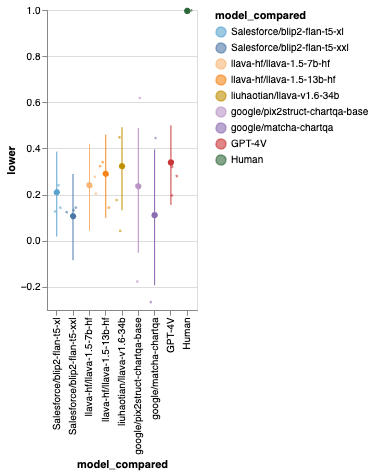

In [231]:
correlation = pd.read_csv("human_model_correlation_df.csv")
correlation_tests = pd.read_csv("human_model_test_df.csv")
model_configs = read_model_configs()
model_order = [model_config['model'] for model_config in model_configs]
color_order = [model_config['color'] for model_config in model_configs]


# Create the plot
ci_chart = alt.Chart(correlation).mark_circle(
    size=40, 
    filled=True,
    strokeWidth=1,
    opacity=1
).encode(
    x=alt.X(
        'model_compared:N',
        scale=alt.Scale(
            domain=model_order,
        )
    ),
    y='correlation:Q',
    color=alt.Color(
        'model_compared',
        scale=alt.Scale(
            domain=model_order,
            range=color_order)
    )
)

ci_error_bars = ci_chart.mark_errorbar().encode(
    y='lower:Q',
    y2='upper:Q',
)

scatter = alt.Chart(correlation_tests).mark_circle(
    size=8, opacity=0.6
).encode(
    x=alt.X('model_compared:N', scale=alt.Scale(domain=model_order)),
    y='correlation:Q',
    xOffset="jitter:Q",
    color=alt.Color(
        'model_compared:N',
        scale=alt.Scale(domain=model_order, range=color_order),
    ),
).transform_calculate(
    jitter="sqrt(-2*log(random()))*cos(2*PI*random())" 
)



chart = scatter + ci_chart + ci_error_bars
chart.properties(title=f"", height=300, width=150)

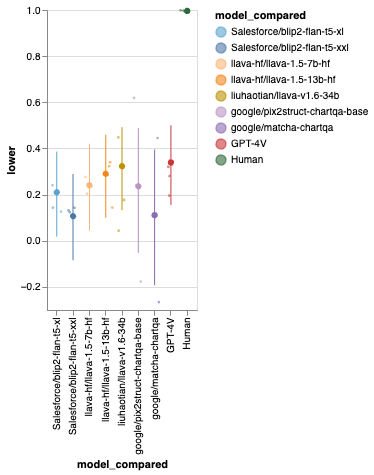

In [230]:
correlation = pd.read_csv("human_model_correlation_df.csv")
correlation_tests = pd.read_csv("human_model_test_df.csv")

model_configs = read_model_configs()
model_order = [model_config['model'] for model_config in model_configs]
color_order = [model_config['color'] for model_config in model_configs]


# Create the plot
ci_chart = alt.Chart(correlation).mark_circle(
    size=40, 
    filled=True,
    strokeWidth=1,
    opacity=1
).encode(
    x=alt.X(
        'model_compared:N',
        scale=alt.Scale(
            domain=model_order,
        )
    ),
    y='correlation:Q',
    color=alt.Color(
        'model_compared',
        scale=alt.Scale(
            domain=model_order,
            range=color_order)
    )
)

ci_error_bars = ci_chart.mark_errorbar().encode(
    y='lower:Q',
    y2='upper:Q',
)

scatter = alt.Chart(correlation_tests).mark_circle(
    size=8, opacity=0.6
).encode(
    x=alt.X('model_compared:N', scale=alt.Scale(domain=model_order)),
    y='correlation:Q',
    xOffset="jitter:Q",
    color=alt.Color(
        'model_compared:N',
        scale=alt.Scale(domain=model_order, range=color_order),
    ),
).transform_calculate(
    jitter="sqrt(-2*log(random()))*cos(2*PI*random())" 
)



chart = scatter + ci_chart + ci_error_bars
chart.properties(title=f"", height=300, width=150)